In [1]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv
import re


load_dotenv()

embeddings_own = OpenAIEmbeddings(model="text-embedding-3-large")
store = InMemoryVectorStore(embeddings_own)

with open("rules.txt", "r", encoding="utf-8") as file:
    text = file.read()

chunks = text.split("\n\n\n")
docs = []
for chunk in chunks:
    protected = re.sub(r'(?<=\d)\.(?=\d)', '<DOT>', chunk)
    sentences = re.split(r'(?<=[.!?])\s+(?=[A-ZА-Я])', protected)
    sentences = [s.replace('<DOT>', '.').strip() for s in sentences]

    for i in sentences:
        docs.append(Document(i, metadata={"source": "rules.txt"}))

some_document = docs
store.store.clear()
store.add_documents(documents=some_document)

['289e4992-a03f-4ea1-8c46-8f690996bd36',
 'ac6150b4-9c20-41da-b94b-524c0a668cb0',
 '8f004a53-0a1b-445d-9d92-49d53b4ed83f',
 '705ca09d-e2a4-4619-98d3-e2273565f790',
 '8421af0f-db7c-4a77-b8b9-f11bc711272f',
 'ccab8138-f2a2-4d06-8780-9c7a91b693ca',
 '4c79adeb-b5d4-4c92-a621-0e5449276fab',
 '541f5198-7352-4c3f-b390-bbfaa467c5cb',
 '2e828ef2-88f2-4a61-a8c9-6457d6a3c6ce',
 '1a6233d2-62a3-4d47-a1fc-7314ae3f1781',
 'f4b52058-33be-4529-8301-a4dce2d09538',
 'f1669c02-7e27-42cb-90ee-1f008f415b6f',
 'c7dbfd07-f80a-44aa-ab58-35e1576b7c91',
 '2a51e973-476a-4b3d-83b1-2b9024748bd5',
 '5d922da3-058f-4f4e-96a9-eba46853a186',
 'e2a4b842-48d3-43a4-bc7a-1ab3dc64ca35',
 'a53b5b5c-7303-4ede-8441-80e7341892fd',
 'e89c10e1-b968-4994-a562-111e987c4e20',
 '791f60d8-2fc1-45d6-860b-87e20132679e',
 '27cd95a3-7271-42f5-b3c7-96f54583f9ce',
 '6e152a0e-a59f-448b-b807-a1785cf9dfe4',
 '995887c2-e900-4681-bab2-5c3af965a94a',
 'aef09052-6118-402e-b272-fa438b729e1a',
 'fbb0616e-f669-40b8-91d1-07d8019d106a',
 '98bd4100-636c-

In [16]:
from langgraph.graph import START, StateGraph, MessagesState, END
from IPython.display import display, Image
import pandas
from langchain_core.documents import Document
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Literal

class MessagesState(MessagesState):
    new_data_frame: pandas.DataFrame
    i: int
    attribute: str
    value: str

def start_node(state: MessagesState) -> MessagesState:
    if (data_frame.shape[0] > state["i"]):
        state["attribute"] = data_frame.iloc[state["i"]]["Attribute"]
        state["value"] = data_frame.iloc[state["i"]]["Value"]
    return state;

def llm_node(state: MessagesState) -> Literal["retrieve_context", "end_node"]:
    if state["i"] < data_frame.shape[0]:
        return "retrieve_context"
    else:
        return "end_node"
    # return {"messages": [llm_with_tools.invoke(state.get("messages"))]}

SYSTEM_PROMPT = """
You are a data normalization engine.

Your task is to normalize the provided attribute value using ONLY the supplied technical rules.

General rules:
- Use only the provided rules as the source of normalization decisions.
- Evaluate every retrieved rule before deciding whether it applies.
- Apply every applicable rule to the value.
- Apply substitutions sequentially until all applicable rules have been processed.
- Ignore any line starting with "Reference:" because it is documentation only and must never affect the output.
- If no rule applies, return the original value unchanged.

Substitution rules:
- A rule may express a substitution in different ways, including:
  - "X becomes Y"
  - "X is abbreviated as Y"
  - "Material codes are ..."
  - "The approved short form is ..."
  - "Use code ..."
  Whenever such a rule matches part of the value, replace only that matching part.
- Preserve all other information from the original value unless a rule explicitly changes it.
- Never remove, truncate, reorder, or invent information unless a rule explicitly instructs you to do so.

Formatting rules:
- If a rule demonstrates formatting using an example (for example "GOST-33259"), treat it as a formatting pattern only.
- Never copy literal example values into the output unless they already exist in the original value.
- Never replace a standard number, year, grade, code, or identifier with a different one mentioned elsewhere in the rules.
- Only modify separators, spacing, capitalization, abbreviations, or units when explicitly required by the rules.

Output requirements:
- Return ONLY the final normalized value.
- Do not explain your reasoning.
- Do not summarize the rules.
- Do not output markdown.
- Do not output bullet lists.
- Do not output any extra text.

Examples:

Attribute: Body material
Value: Grey cast iron GG-20
Rules:
Material codes are GCI for grey cast iron, CS for carbon steel, and SS for stainless steel.
Output:
GCI GG-20

Attribute: Seal material
Value: Stainless steel 12Cr18Ni9Ti
Rules:
Material codes are GCI for grey cast iron, CS for carbon steel, and SS for stainless steel.
Output:
SS 12Cr18Ni9Ti

Attribute: End connection
Value: Flanged
Rules:
FLANGED becomes FLG.
Output:
FLG

Attribute: Valve type
Value: Gate valve, wedge
Rules:
GATE VALVE becomes GV.
Output:
GV, wedge
"""

def retrieve_context(state: MessagesState) -> MessagesState:
    """Retrieve information to help answer a query and return list of documents."""
    retrived_documents = store.similarity_search(query = f"{state['attribute']}: {state['value']}", k=8)
    contexts = "\n\n".join(f"{doc.page_content}" for doc in retrived_documents)
    # print(f"Retrieved documents: {retrived_documents}\n\n\nContext documents: {contexts}")
    new_iteration = state.get("i") + 1
    inv = model.invoke([{"role": "system", "content": SYSTEM_PROMPT}, {"role": 'user', "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"}])

    new_row = pandas.DataFrame([{"Attribute": state["attribute"],
                                 "Value": state["value"],
                                 "Rules_Value": inv.content}])

    updated_data_frame = pandas.concat([state["new_data_frame"], new_row], ignore_index=True)

    return {"messages": [inv, contexts], "i": new_iteration, "new_data_frame": updated_data_frame}

def end_node(state: MessagesState) -> MessagesState:
    file = state.get("new_data_frame")
    file.to_excel("test_first_phase_table1.xlsx", index=False)
    return state

load_dotenv()


data_frame = pandas.read_excel("attributes.xlsx")

# tools = [retrieve_context]
# tools_node = ToolNode(tools)

model = ChatOpenAI(model="gpt-4o", temperature=0)
# llm_with_tools = model.bind_tools(tools)

builder = StateGraph(MessagesState)
builder.add_node(start_node)
builder.add_node(retrieve_context)
builder.add_node(end_node)
builder.add_edge(START, "start_node")
builder.add_conditional_edges("start_node", llm_node)
builder.add_edge("retrieve_context", "start_node")
builder.add_edge("end_node", END)

graph = builder.compile()

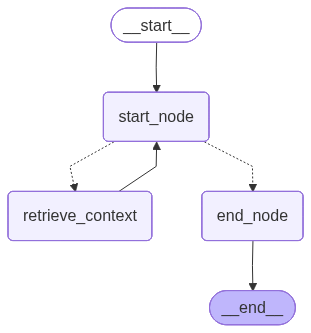

In [4]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [18]:
data_frame = pandas.read_excel("test_attributes.xlsx")
data_frame

,Attribute,Value
0,Valve type,"Ball valve, full bore"
1,"Nominal diameter, mm",80
2,"Nominal pressure, bar",16 bar
3,Working medium,Oil
4,"Working medium temperature, F",212 F
5,Body material,Carbon steel 25L
6,Seal material,Stainless steel 12Cr18Ni9Ti
7,Actuator type,Electric actuator
8,"Face-to-face length, in",9.84 in
9,"Weight, lb",40 lb


In [19]:
result = graph.invoke({"messages": [], 'new_data_frame': pandas.DataFrame(columns=["Attribute", "Value", "Rules_Value"]), "i":0})

for f in result["messages"]:
    f.pretty_print()

================================== Ai Message ==================================

BV, full bore
================================ Human Message =================================

The following substitutions
apply: GATE VALVE becomes GV, BALL VALVE becomes BV, BUTTERFLY VALVE becomes BFV,
and CHECK VALVE becomes CV.

LEAKAGE AND CONNECTION

The valve must comply with the leakage class declared in its specification.

The face-to-face length for a gate valve at
DN100 is 250 mm in the short dimensional series and 350 mm in the long series.

PIPELINE VALVE COMPONENT RULES AND STANDARDS
Technical Reference Document — Internal Use Only

The nominal diameter must belong to the standard DN series: 15, 20, 25,
32, 40, 50, 65, 80, 100, 125, 150, 200, and so on.

The end connection type must correspond to the pressure
class and nominal diameter.

Flanged connections are mandatory for DN 50 mm and above
at PN 1.0 MPa and higher.

DIMENSIONS AND WEIGHT

All linear dimensions, including face-to-face l